In [3]:
import pandas as pd
from pathlib import Path

# Project data folder
data_folder = Path(r"C:\customer-churn-prediction\data")

# Find CSV file
csv_files = list(data_folder.glob("*.csv"))

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

# Load dataset
df = pd.read_csv(csv_files[0])

print("\nDataset shape:", df.shape)

df.head()


CSV files found: 1
WA_Fn-UseC_-Telco-Customer-Churn.csv

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
from sklearn.model_selection import train_test_split

# Select a representative 3,000-customer subset
df_3000, _ = train_test_split(
    df,
    train_size=3000,
    stratify=df["Churn"],
    random_state=42
)

# Reset index
df_3000 = df_3000.reset_index(drop=True)

# Check result
print("Original dataset:", df.shape)
print("Lightweight dataset:", df_3000.shape)

print("\nChurn distribution:")
print(df_3000["Churn"].value_counts())

print("\nChurn percentage:")
print((df_3000["Churn"].value_counts(normalize=True) * 100).round(2))

Original dataset: (7043, 21)
Lightweight dataset: (3000, 21)

Churn distribution:
Churn
No     2204
Yes     796
Name: count, dtype: int64

Churn percentage:
Churn
No     73.47
Yes    26.53
Name: proportion, dtype: float64


In [6]:
from pathlib import Path

# Output path for lightweight dataset
output_path = Path(r"C:\customer-churn-prediction\data\customer_churn.csv")

# Save 3,000-row dataset
df_3000.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Location:", output_path)
print("Rows:", len(df_3000))
print("Columns:", len(df_3000.columns))

Dataset saved successfully!
Location: C:\customer-churn-prediction\data\customer_churn.csv
Rows: 3000
Columns: 21


In [7]:
# Verify saved dataset
df = pd.read_csv(r"C:\customer-churn-prediction\data\customer_churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (3000, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7718-UPSKJ,Female,0,Yes,No,69,Yes,No,Fiber optic,Yes,...,No,Yes,Yes,Yes,One year,Yes,Credit card (automatic),106.40,7251.9,No
1,2688-BHGOG,Male,1,No,No,9,Yes,No,Fiber optic,No,...,No,No,No,Yes,Month-to-month,Yes,Electronic check,79.55,718.55,No
2,6732-VAILE,Male,0,Yes,Yes,70,Yes,Yes,DSL,No,...,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),85.95,5931.75,No
3,5886-VLQVU,Male,0,Yes,No,35,Yes,Yes,Fiber optic,No,...,No,Yes,No,Yes,Month-to-month,Yes,Bank transfer (automatic),89.85,3161.2,No
4,5172-MIGPM,Male,0,No,No,4,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Mailed check,65.55,237.2,No


In [8]:
# Basic dataset information

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (3000, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Dataset Information

In [9]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

Missing Values:
Series([], dtype: int64)

Total missing values: 0


In [10]:
# Check duplicate records

duplicates = df.duplicated().sum()

print("Duplicate records:", duplicates)

Duplicate records: 0


In [11]:
# Check unique values in categorical columns

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


customerID:
<ArrowStringArray>
['7718-UPSKJ', '2688-BHGOG', '6732-VAILE', '5886-VLQVU', '5172-MIGPM',
 '8972-HJWNV', '4632-XJMEX', '8336-TAVKX', '6586-MYGKD', '2037-XJFUP',
 ...
 '0565-JUPYD', '7683-CBDKJ', '8695-WDYEA', '6257-DTAYD', '6308-CQRBU',
 '5071-FBJFS', '4822-RVYBB', '5480-XTFFL', '4065-JJAVA', '2153-MREFK']
Length: 3000, dtype: str

gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Partner:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Dependents:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

PhoneService:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

MultipleLines:
<ArrowStringArray>
['No', 'Yes', 'No phone service']
Length: 3, dtype: str

InternetService:
<ArrowStringArray>
['Fiber optic', 'DSL', 'No']
Length: 3, dtype: str

OnlineSecurity:
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

OnlineBackup:
<ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str

DeviceProtecti

C:\Users\Muneeba Asjad\AppData\Local\Temp\ipykernel_13588\918245467.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [12]:
# Convert TotalCharges from string to numeric
# Invalid/blank values will become NaN

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)

print("\nMissing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

TotalCharges data type: float64

Missing TotalCharges after conversion:
6


In [18]:
# Median imputation for TotalCharges

if df["TotalCharges"].isnull().sum() > 0:
    median_total_charges = df["TotalCharges"].median()

    df["TotalCharges"] = df["TotalCharges"].fillna(
        median_total_charges
    )

    print("Missing TotalCharges values filled using median:")
    print(median_total_charges)
else:
    print("No missing TotalCharges values found.")

print("\nRemaining missing values:")
print(df.isnull().sum().sum())

No missing TotalCharges values found.

Remaining missing values:
0


In [17]:
# Check for duplicate customer records

duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


In [16]:
# Save cleaned dataset

cleaned_path = r"C:\customer-churn-prediction\data\customer_churn_cleaned.csv"

df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_path)
print("Shape:", df.shape)

Cleaned dataset saved successfully!
Location: C:\customer-churn-prediction\data\customer_churn_cleaned.csv
Shape: (3000, 21)


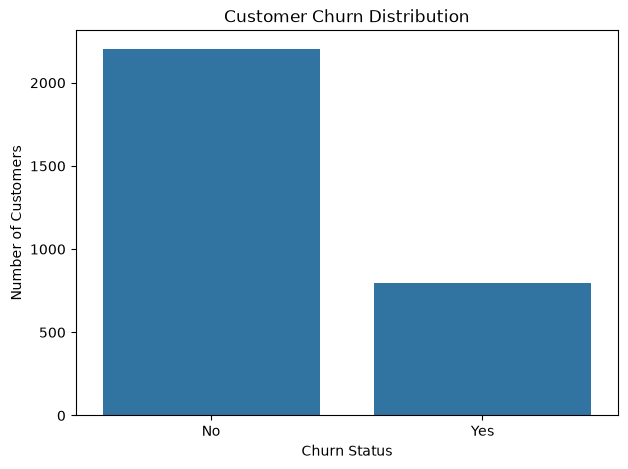

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Churn distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [20]:
churn_percentage = (
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Churn Percentage:")
print(churn_percentage)

Churn Percentage:
Churn
No     73.47
Yes    26.53
Name: proportion, dtype: float64


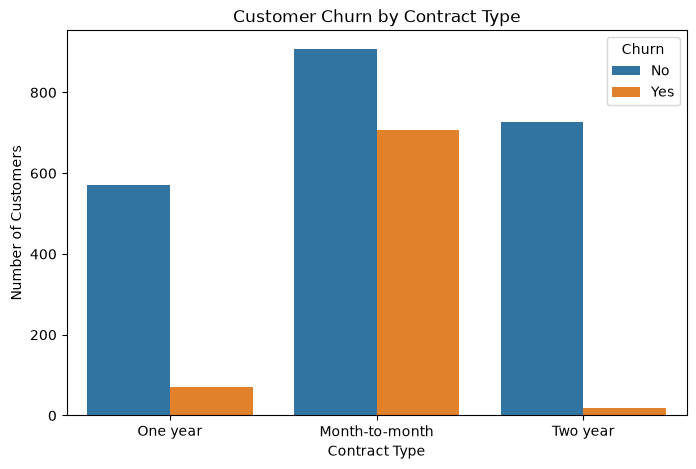

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

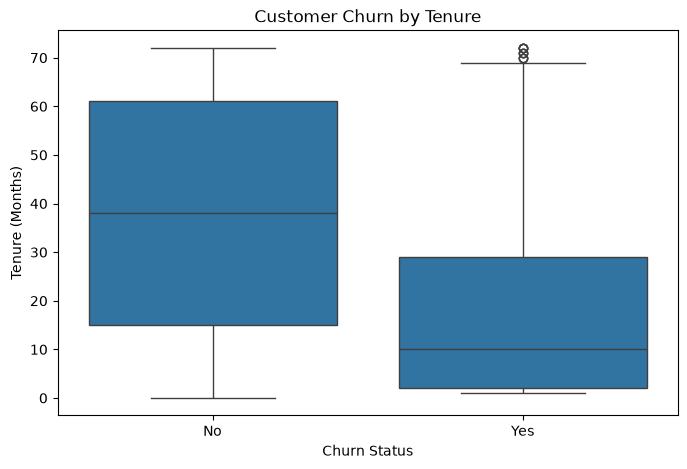

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()

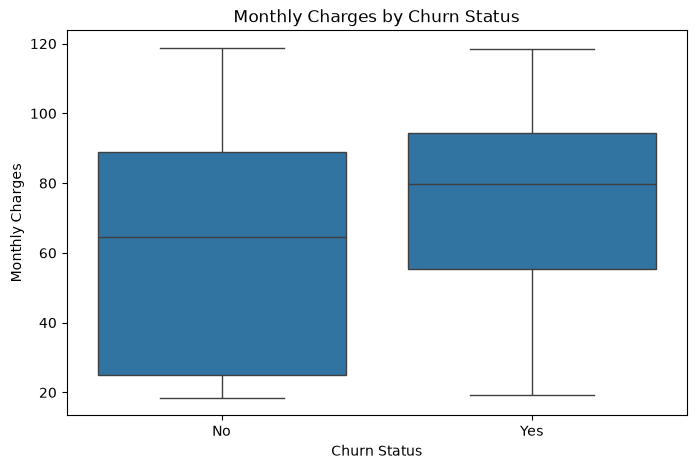

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

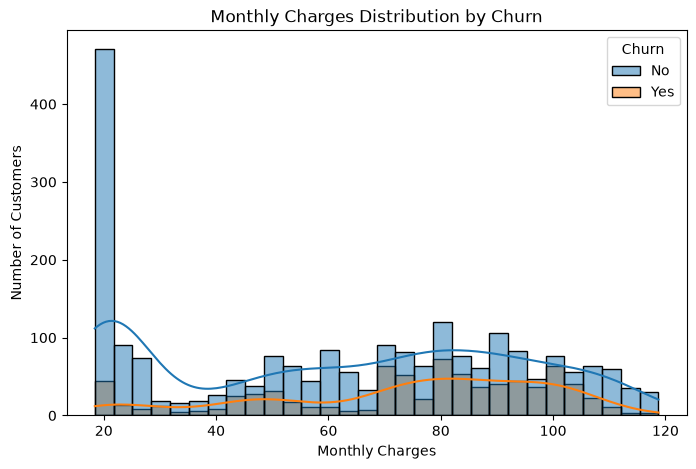

In [24]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")

plt.show()

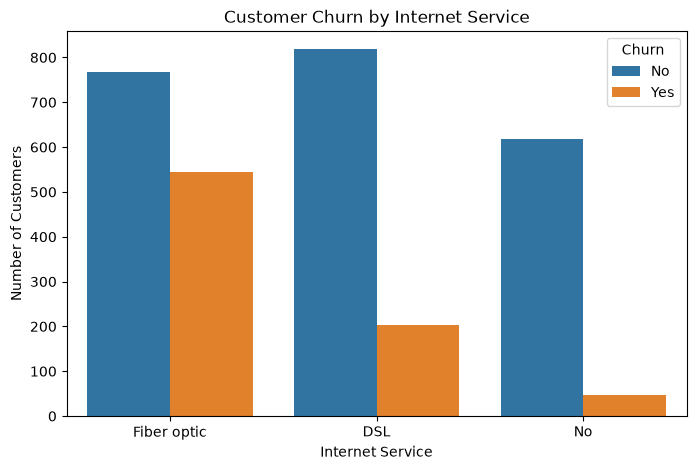

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

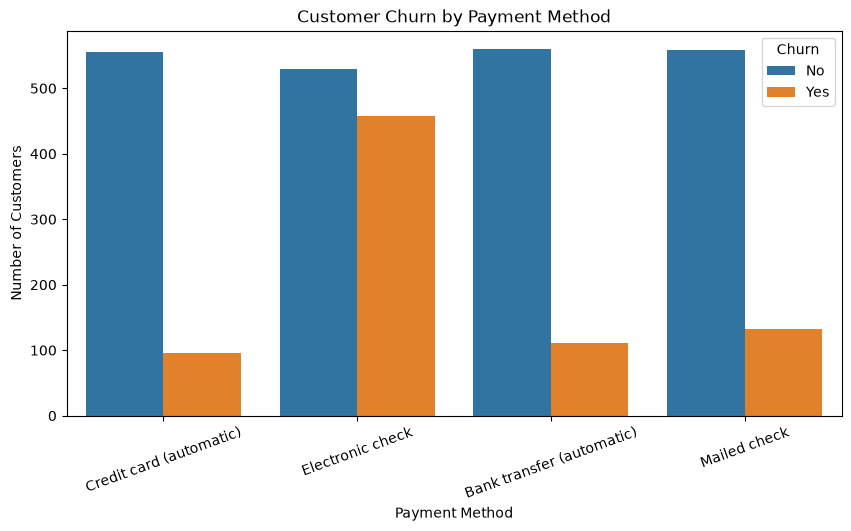

In [26]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

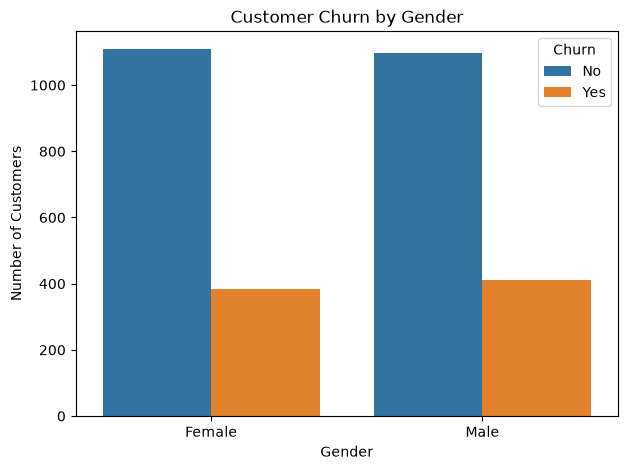

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="gender",
    hue="Churn"
)

plt.title("Customer Churn by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

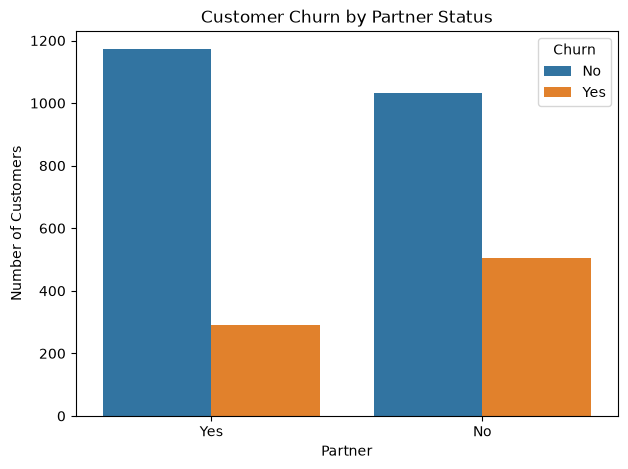

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn"
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Partner")
plt.ylabel("Number of Customers")

plt.show()

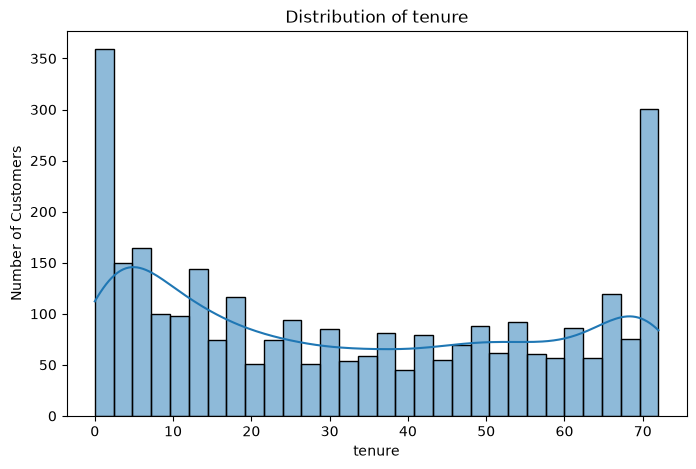

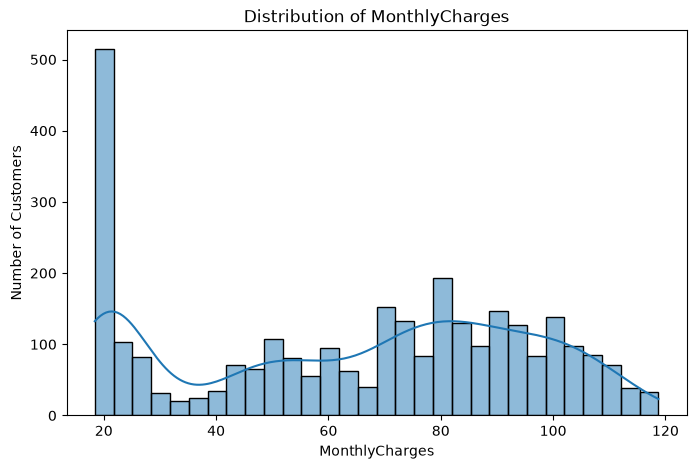

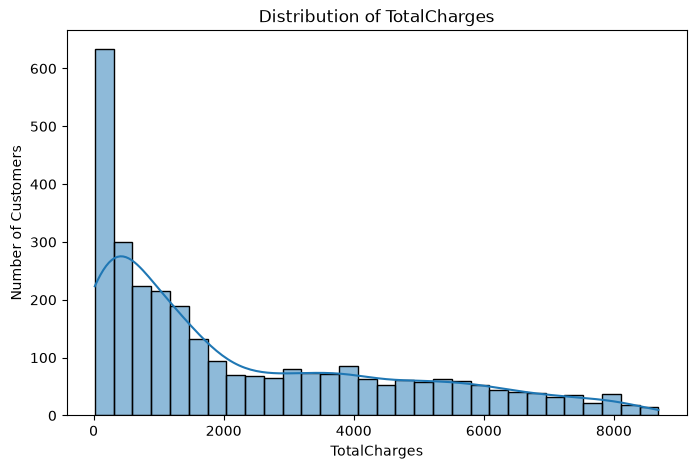

In [29]:
# Distribution of numerical features

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Customers")

    plt.show()

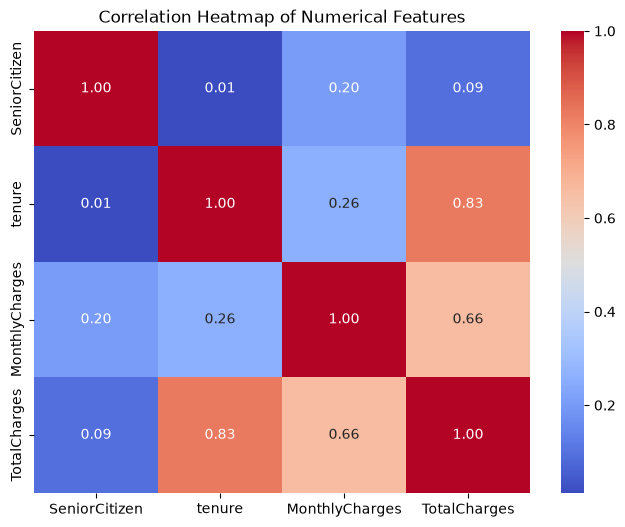

In [30]:
# Correlation heatmap

correlation_data = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_data,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")

plt.show()

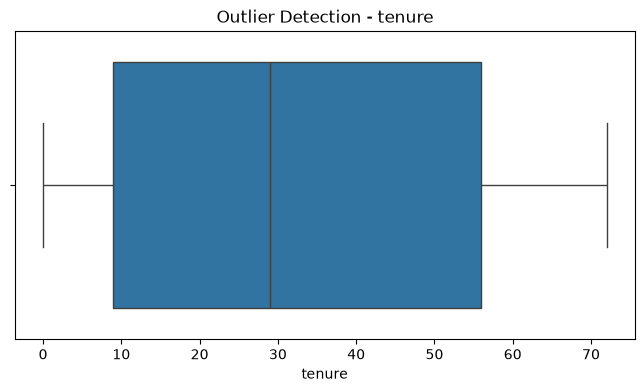

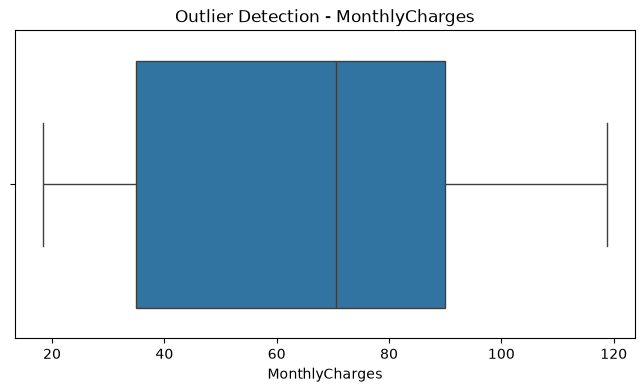

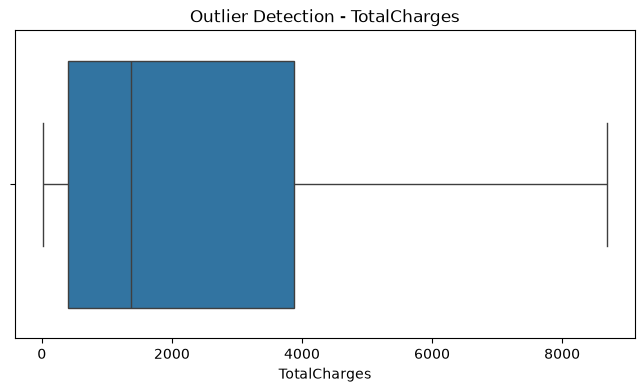

In [31]:
# Boxplots for numerical features

for feature in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[feature]
    )

    plt.title(f"Outlier Detection - {feature}")
    plt.xlabel(feature)

    plt.show()

In [32]:
# Calculate churn rate by contract type

contract_churn = (
    pd.crosstab(
        df["Contract"],
        df["Churn"],
        normalize="index"
    ) * 100
)

contract_churn = contract_churn.round(2)

print("Churn Rate by Contract Type:")
print(contract_churn)

Churn Rate by Contract Type:
Churn              No    Yes
Contract                    
Month-to-month  56.22  43.78
One year        88.92  11.08
Two year        97.58   2.42


In [33]:
internet_churn = (
    pd.crosstab(
        df["InternetService"],
        df["Churn"],
        normalize="index"
    ) * 100
)

internet_churn = internet_churn.round(2)

print("Churn Rate by Internet Service:")
print(internet_churn)

Churn Rate by Internet Service:
Churn               No    Yes
InternetService              
DSL              80.04  19.96
Fiber optic      58.50  41.50
No               92.80   7.20


In [34]:
payment_churn = (
    pd.crosstab(
        df["PaymentMethod"],
        df["Churn"],
        normalize="index"
    ) * 100
)

payment_churn = payment_churn.round(2)

print("Churn Rate by Payment Method:")
print(payment_churn)

Churn Rate by Payment Method:
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.46  16.54
Credit card (automatic)    85.28  14.72
Electronic check           53.65  46.35
Mailed check               80.90  19.10


In [35]:
# Tenure segmentation

def tenure_segment(tenure):
    if tenure <= 12:
        return "New Customer"
    elif tenure <= 48:
        return "Regular Customer"
    else:
        return "Loyal Customer"


df["TenureSegment"] = df["tenure"].apply(tenure_segment)

print("Tenure Segment Distribution:")
print(df["TenureSegment"].value_counts())

Tenure Segment Distribution:
TenureSegment
Regular Customer    1108
Loyal Customer       965
New Customer         927
Name: count, dtype: int64


In [36]:
# Monthly charges classification using quantiles

df["MonthlyChargesCategory"] = pd.qcut(
    df["MonthlyCharges"],
    q=3,
    labels=["Low Spend", "Medium Spend", "High Spend"]
)

print("Monthly Charges Category Distribution:")
print(df["MonthlyChargesCategory"].value_counts())

Monthly Charges Category Distribution:
MonthlyChargesCategory
Low Spend       1001
Medium Spend    1000
High Spend       999
Name: count, dtype: int64


In [37]:
# Calculate total revenue generated by each customer

df["TotalRevenue"] = df["MonthlyCharges"] * df["tenure"]

print("TotalRevenue created successfully.")

df[["tenure", "MonthlyCharges", "TotalRevenue"]].head()

TotalRevenue created successfully.


,tenure,MonthlyCharges,TotalRevenue
0,69,106.40,7341.60
1,9,79.55,715.95
2,70,85.95,6016.50
3,35,89.85,3144.75
4,4,65.55,262.20


In [38]:
# Calculate total number of subscribed services

service_columns = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["ServiceCount"] = 0

for column in service_columns:
    df["ServiceCount"] += (
        df[column]
        .isin(["Yes", "DSL", "Fiber optic"])
        .astype(int)
    )

print("ServiceCount created successfully.")

df[["ServiceCount", "Churn"]].head()

ServiceCount created successfully.


,ServiceCount,Churn
0,7,No
1,3,No
2,8,No
3,5,No
4,5,No


In [39]:
# Contract risk score

contract_risk_mapping = {
    "Month-to-month": 3,
    "One year": 2,
    "Two year": 1
}

df["ContractRiskScore"] = df["Contract"].map(
    contract_risk_mapping
)

print("Contract Risk Score Distribution:")
print(df["ContractRiskScore"].value_counts().sort_index())

Contract Risk Score Distribution:
ContractRiskScore
1     744
2     641
3    1615
Name: count, dtype: int64


In [40]:
# Check all engineered features

engineered_features = [
    "TenureSegment",
    "MonthlyChargesCategory",
    "TotalRevenue",
    "ServiceCount",
    "ContractRiskScore"
]

print("Engineered Features:")
print(engineered_features)

print("\nSample:")
display(
    df[
        [
            "customerID",
            "tenure",
            "TenureSegment",
            "MonthlyCharges",
            "MonthlyChargesCategory",
            "TotalRevenue",
            "ServiceCount",
            "Contract",
            "ContractRiskScore",
            "Churn"
        ]
    ].head(10)
)

Engineered Features:
['TenureSegment', 'MonthlyChargesCategory', 'TotalRevenue', 'ServiceCount', 'ContractRiskScore']

Sample:


,customerID,tenure,TenureSegment,MonthlyCharges,MonthlyChargesCategory,TotalRevenue,ServiceCount,Contract,ContractRiskScore,Churn
0,7718-UPSKJ,69,Loyal Customer,106.40,High Spend,7341.60,7,One year,2,No
1,2688-BHGOG,9,New Customer,79.55,Medium Spend,715.95,3,Month-to-month,3,No
2,6732-VAILE,70,Loyal Customer,85.95,High Spend,6016.50,8,Two year,1,No
3,5886-VLQVU,35,Regular Customer,89.85,High Spend,3144.75,5,Month-to-month,3,No
4,5172-MIGPM,4,New Customer,65.55,Medium Spend,262.20,5,Month-to-month,3,No
5,8972-HJWNV,7,New Customer,84.55,High Spend,591.85,4,Month-to-month,3,Yes
6,4632-XJMEX,53,Loyal Customer,62.85,Medium Spend,3331.05,5,One year,2,No
7,8336-TAVKX,72,Loyal Customer,78.45,Medium Spend,5648.40,8,Two year,1,No
8,6586-MYGKD,70,Loyal Customer,76.95,Medium Spend,5386.50,7,Two year,1,No
9,2037-XJFUP,33,Regular Customer,95.80,High Spend,3161.40,5,One year,2,Yes


In [41]:
# Check dataset after feature engineering

print("Dataset shape:", df.shape)

print("\nAll columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (3000, 26)

All columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureSegment', 'MonthlyChargesCategory', 'TotalRevenue', 'ServiceCount', 'ContractRiskScore']

Missing values:
0


In [42]:
# Encode target variable

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Target distribution:")
print(df["Churn"].value_counts())

Target distribution:
Churn
0    2204
1     796
Name: count, dtype: int64


In [43]:
# Remove customer ID from machine learning features

df_model = df.drop(columns=["customerID"])

print("Dataset shape for modeling:", df_model.shape)

Dataset shape for modeling: (3000, 25)


In [44]:
# Separate input features and target

X = df_model.drop(columns=["Churn"])
y = df_model["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3000, 24)
Target shape: (3000,)


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (2400, 24)
Testing data: (600, 24)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [46]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalRevenue', 'ServiceCount', 'ContractRiskScore']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureSegment']


In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    drop="if_binary"
)

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [49]:
try:
    import xgboost
    print("XGBoost version:", xgboost.__version__)
except ImportError:
    print("XGBoost is not installed yet.")

XGBoost version: 2.1.4


In [50]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [51]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [52]:
from xgboost import XGBClassifier

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=150,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgboost_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [53]:
# Generate predictions for all three models

logistic_pred = logistic_model.predict(X_test)
random_forest_pred = random_forest_model.predict(X_test)
xgboost_pred = xgboost_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Probability predictions
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
random_forest_prob = random_forest_model.predict_proba(X_test)[:, 1]
xgboost_prob = xgboost_model.predict_proba(X_test)[:, 1]


def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }


results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        logistic_pred,
        logistic_prob
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        random_forest_pred,
        random_forest_prob
    )
)

results.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgboost_pred,
        xgboost_prob
    )
)

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8067,0.6483,0.5912,0.6184,0.8507
1,Random Forest,0.8167,0.6763,0.5912,0.6309,0.8442
2,XGBoost,0.8083,0.6467,0.6101,0.6278,0.8509


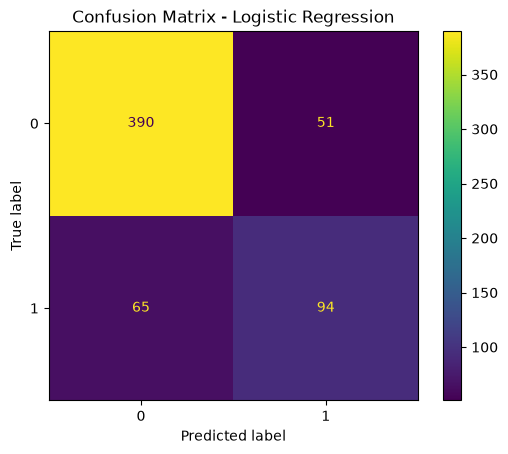

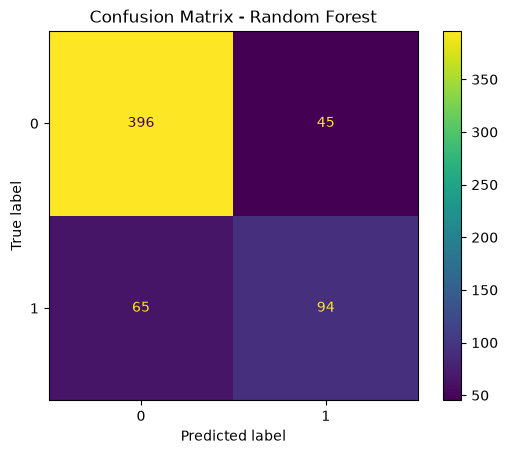

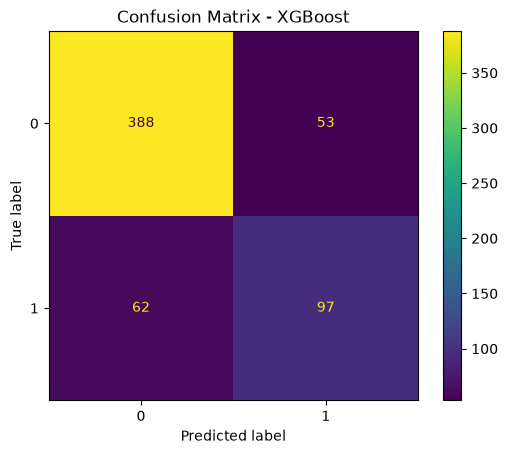

In [55]:
from sklearn.metrics import ConfusionMatrixDisplay

models_predictions = {
    "Logistic Regression": logistic_pred,
    "Random Forest": random_forest_pred,
    "XGBoost": xgboost_pred
}

for name, predictions in models_predictions.items():

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

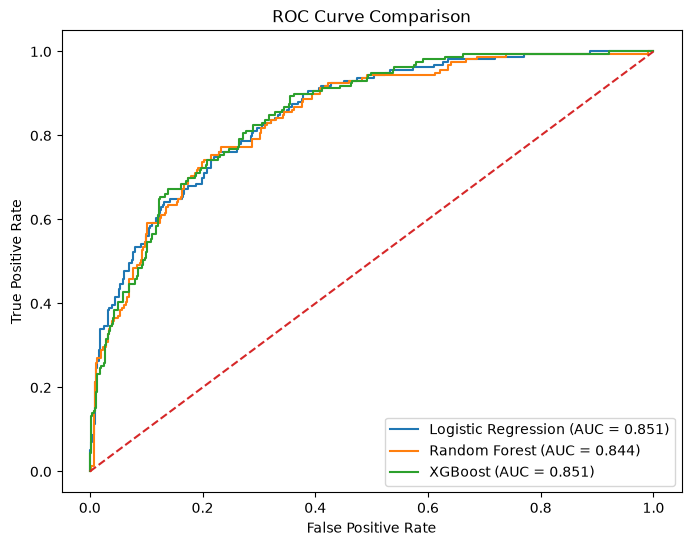

In [56]:
from sklearn.metrics import roc_curve

model_probabilities = {
    "Logistic Regression": logistic_prob,
    "Random Forest": random_forest_prob,
    "XGBoost": xgboost_prob
}

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

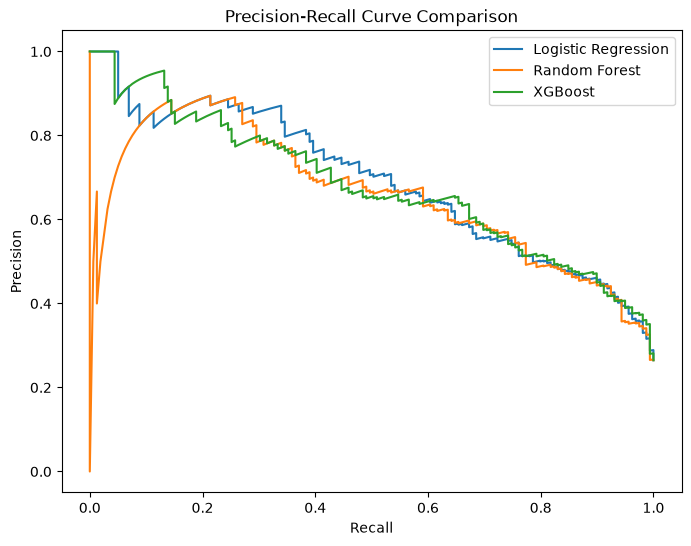

In [57]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8, 6))

for name, probabilities in model_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()

plt.show()

In [58]:
# Sort models according to Recall

results_sorted = results_df.sort_values(
    by=["Recall", "ROC-AUC"],
    ascending=False
).reset_index(drop=True)

print("Model Performance Comparison:")
display(results_sorted.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.8083,0.6467,0.6101,0.6278,0.8509
1,Logistic Regression,0.8067,0.6483,0.5912,0.6184,0.8507
2,Random Forest,0.8167,0.6763,0.5912,0.6309,0.8442


In [61]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_cv_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Logistic Regression 5-Fold ROC-AUC Scores:")
print(logistic_cv_scores.round(4))

print("\nMean ROC-AUC:", round(logistic_cv_scores.mean(), 4))
print("Standard Deviation:", round(logistic_cv_scores.std(), 4))

Logistic Regression 5-Fold ROC-AUC Scores:
[0.8678 0.853  0.8571 0.8362 0.839 ]

Mean ROC-AUC: 0.8506
Standard Deviation: 0.0117


In [62]:
random_forest_cv_scores = cross_val_score(
    random_forest_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest 5-Fold ROC-AUC Scores:")
print(random_forest_cv_scores.round(4))

print("\nMean ROC-AUC:", round(random_forest_cv_scores.mean(), 4))
print("Standard Deviation:", round(random_forest_cv_scores.std(), 4))

Random Forest 5-Fold ROC-AUC Scores:
[0.865  0.8487 0.849  0.8354 0.8294]

Mean ROC-AUC: 0.8455
Standard Deviation: 0.0123


In [63]:
xgboost_cv_scores = cross_val_score(
    xgboost_model,
    X,
    y,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("XGBoost 5-Fold ROC-AUC Scores:")
print(xgboost_cv_scores.round(4))

print("\nMean ROC-AUC:", round(xgboost_cv_scores.mean(), 4))
print("Standard Deviation:", round(xgboost_cv_scores.std(), 4))

XGBoost 5-Fold ROC-AUC Scores:
[0.8699 0.8579 0.8496 0.8395 0.8382]

Mean ROC-AUC: 0.851
Standard Deviation: 0.0118


In [64]:
# Get transformed feature names

feature_names = xgboost_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get XGBoost feature importance

importance_values = xgboost_model.named_steps[
    "classifier"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Churn Influencing Features:")
display(feature_importance.head(15))

Top 15 Churn Influencing Features:


,Feature,Importance
0,cat__Contract_Month-to-month,0.297127
1,num__ContractRiskScore,0.135782
2,cat__TenureSegment_New Customer,0.104369
3,cat__InternetService_Fiber optic,0.036992
4,cat__OnlineSecurity_No,0.036566
5,cat__TechSupport_No,0.023965
6,cat__Contract_Two year,0.021417
7,cat__TenureSegment_Loyal Customer,0.019545
8,num__tenure,0.015773
9,cat__InternetService_DSL,0.015644


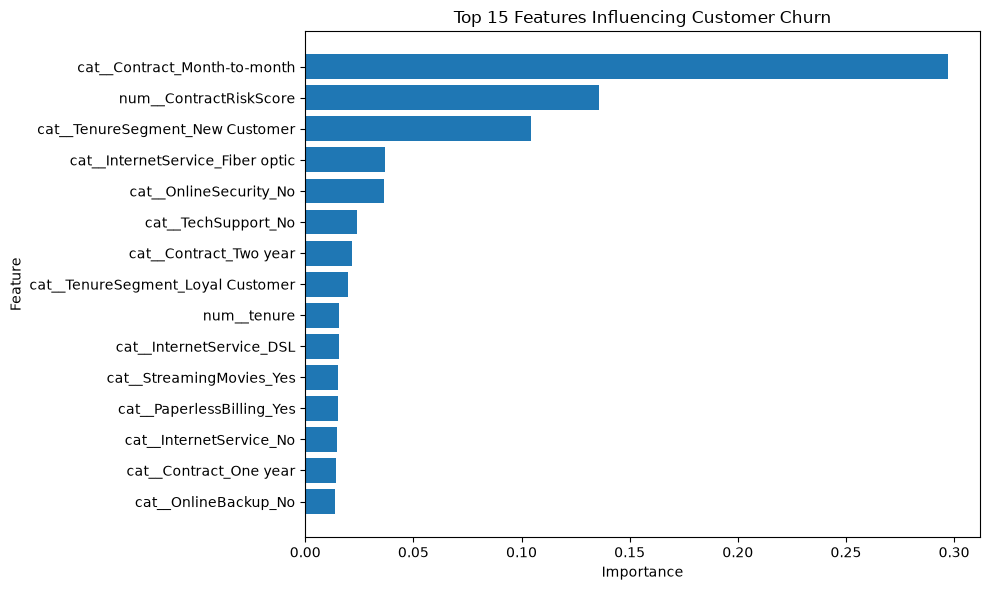

In [65]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
feature_importance.to_csv(
    "data/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [67]:
# Select best model based on Recall and ROC-AUC

best_model_name = results_sorted.iloc[0]["Model"]

print("Selected Best Model:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = logistic_model
elif best_model_name == "Random Forest":
    best_model = random_forest_model
else:
    best_model = xgboost_model

print("Best model selected successfully!")

Selected Best Model: XGBoost
Best model selected successfully!


In [68]:
# Display final model performance

best_result = results_sorted[
    results_sorted["Model"] == best_model_name
]

display(best_result.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.8083,0.6467,0.6101,0.6278,0.8509


In [69]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/churn_prediction_model.pkl"
)

print("Final model saved successfully!")
print("Location: models/churn_prediction_model.pkl")

Final model saved successfully!
Location: models/churn_prediction_model.pkl


In [70]:
# Save processed dataset

os.makedirs("data", exist_ok=True)

df.to_csv(
    "data/customer_churn_processed.csv",
    index=False
)

print("Processed dataset saved successfully!")
print("Location: data/customer_churn_processed.csv")
print("Shape:", df.shape)

Processed dataset saved successfully!
Location: data/customer_churn_processed.csv
Shape: (3000, 26)


In [71]:
# Save model comparison results

results_df.to_csv(
    "data/model_performance.csv",
    index=False
)

print("Model performance saved successfully!")

Model performance saved successfully!


In [72]:
# Test loading saved model

loaded_model = joblib.load(
    "models/churn_prediction_model.pkl"
)

test_predictions = loaded_model.predict(X_test)

print("Saved model loaded successfully!")
print("Test predictions generated:", len(test_predictions))

Saved model loaded successfully!
Test predictions generated: 600


In [73]:
import os

print("Project files:")

for root, dirs, files in os.walk("."):
    for file in files:
        if (
            file.endswith(".csv")
            or file.endswith(".pkl")
            or file.endswith(".ipynb")
        ):
            print(os.path.join(root, file))

Project files:
.\customer_churn_analysis.ipynb
.\Untitled.ipynb
.\.ipynb_checkpoints\customer_churn_analysis-checkpoint.ipynb
.\.ipynb_checkpoints\Untitled-checkpoint.ipynb
.\data\customer_churn.csv
.\data\customer_churn_cleaned.csv
.\data\customer_churn_processed.csv
.\data\feature_importance.csv
.\data\model_performance.csv
.\data\WA_Fn-UseC_-Telco-Customer-Churn.csv
.\models\churn_prediction_model.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py27_np17.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py33_np18.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py34_np19.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_pickle_py35_np19.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.11.0_pickle_py36_np111.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np16.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_pickle_py27_np17.pkl
.\venv\Lib\site-packages\joblib\test\data\joblib_0.9.2